In [8]:
pip install numpy

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [9]:
pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [10]:
pip install qutip

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


# Fig. 2 — the Hamiltonian does the protecting

Same mirror active-pair code (edge placement), exact closed-system dynamics, no Pauli noise:

$$H = J_z H_0^{(1)} + V,\qquad H_0^{(1)}=\sum_{i<j}|i-j|^{-\alpha}\sigma^z_i\sigma^z_j,\qquad V=B_x\sum_i\sigma^x_i+J_x\sum_i\sigma^x_i\sigma^x_{i+1}.$$

* **(a)** $p_{\rm flag}(t)=1-\tfrac12{\rm Tr}[A^\dagger A]$ with $A(t)=PU(t)P$ restricted to the codespace, for $H_0+V$ and for $V$ only ($J_z=0$).
* **(b)** time-averaged $p_{\rm flag}$ versus $J_z/J_x$, against the two-level prediction summed over every single-step channel out of the codewords (hops, $B_x$ flips, pair creation/annihilation).

**Method.** Operators are built with QuTiP in the full $2^N$ space. Everything commutes with reflection $\mathcal R$ and the codewords are $\mathcal R$-even, so we diagonalize $H$ in the reflection-even block (dimension $\approx 2^{N-1}$) and propagate exactly from the eigendecomposition. This handles $J_xt$ up to $10^3$ with $J_z/J_x$ up to $10^3$, where an ODE solver would need far too many steps. A `sesolve` run in the full space cross-checks the block propagation at short times.

**Conventions.** $|{\uparrow}\rangle$ = `basis(2,0)`, $\sigma^z=+1$: empty site. $|{\downarrow}\rangle$ = `basis(2,1)`, $\sigma^z=-1$: excitation. $\hat n_i=(1-\sigma^z_i)/2$. Sites are 1-based in the text and 0-based in the code where noted.

**Cost at N = 14:** block dimension 8256, about 1–2 min and about 1.5 GB per diagonalization, 10 diagonalizations in total. **Set `N = 8` and the matching code in the parameter cell for a 10-second test run.**

In [11]:
import numpy as np, scipy.sparse as sp, time, itertools
import qutip as qt
import matplotlib.pyplot as plt
print("qutip", qt.__version__, "| numpy", np.__version__)

qutip 5.0.4 | numpy 2.0.2


## Parameters

In [12]:
N      = 14          # chain length (even)
alpha  = 0.4
Jx, Bx = 1.0, 0.1    # residual nearest-neighbour coupling and stray field (the perturbation V)
Jz_main = 100.0      # panel (a)
Jz_scan = np.array([0.3, 1, 3, 10, 30, 100, 300, 1000])   # panel (b)

# Optimal b=4 mirror code at N=14, alpha=0.4, J_z/J_x=100 (from the in-sector code scan).
# 1-based occupied sites of the branches |S> (logical 0) and |S'> (logical 1).
code_S, code_Sp = (1, 2, 11, 12), (1, 4, 12, 13)
# --- quick test: N = 8 with code_S, code_Sp = (1, 2, 5, 6), (1, 4, 6, 7) ---

times = np.logspace(-2, 3, 81)   # J_x t for panel (a)
t_avg = np.logspace(0, 3, 400)   # averaging window J_x t in [1, 1000] for panel (b)
assert N % 2 == 0 and max(code_S + code_Sp) <= N

## Operators (QuTiP, full space)

In [13]:
t0 = time.time()
I2, sx, sz = qt.qeye(2), qt.sigmax(), qt.sigmaz()
def op(single, i):
    # single-site operator on site i (0-based), identity elsewhere
    ops = [I2] * N; ops[i] = single
    return qt.tensor(ops).to("csr")
SX = [op(sx, i) for i in range(N)]
SZ = [op(sz, i) for i in range(N)]
nhat = [(1 - z) / 2 for z in SZ]           # excitation number on site i

H0_unit = sum(abs(i - j) ** -alpha * SZ[i] * SZ[j] for i in range(N) for j in range(i + 1, N))
V = Bx * sum(SX) + Jx * sum(SX[i] * SX[i + 1] for i in range(N - 1))
Nexc = sum(nhat)
print(f"built in {time.time()-t0:.1f}s, dim = {2**N}")

built in 0.1s, dim = 16384


### Reflection operator $\mathcal R$ ($i\to N+1-i$)
In the computational basis $\mathcal R$ is a permutation: it reverses the bit string.

In [14]:
dim = 2 ** N
def mirror(s):  # reverse the N-bit string (bit for site 0 is the most significant, as in qt.tensor ordering)
    return int(format(s, f"0{N}b")[::-1], 2)
perm = np.array([mirror(s) for s in range(dim)])
R = qt.Qobj(sp.csr_matrix((np.ones(dim), (perm, np.arange(dim))), shape=(dim, dim)), dims=H0_unit.dims)

### Check 1: Hermiticity and symmetries

In [15]:
def comm_norm(A, B):
    return (A * B - B * A).norm("max")
checks = {
    "H0 Hermitian":        (H0_unit - H0_unit.dag()).norm("max"),
    "V Hermitian":         (V - V.dag()).norm("max"),
    "[H0, R]":             comm_norm(H0_unit, R),
    "[V, R]":              comm_norm(V, R),
    "[H0, N_exc]":         comm_norm(H0_unit, Nexc),
    "R^2 - 1":             (R * R - qt.qeye(R.dims[0])).norm("max"),
}
for k, val in checks.items():
    print(f"{k:16s} {val:.1e}")
    assert val < 1e-10, k
print("[V, N_exc] (should be NONZERO: V changes the sector):", f"{comm_norm(V, Nexc):.2f}")

H0 Hermitian     0.0e+00
V Hermitian      0.0e+00
[H0, R]          2.8e-14
[V, R]           0.0e+00
[H0, N_exc]      0.0e+00
R^2 - 1          0.0e+00
[V, N_exc] (should be NONZERO: V changes the sector): 2.00


## Codewords
$|v_S\rangle=(|S\rangle+|S^c\rangle)/\sqrt2$, where $|S^c\rangle=\mathcal R|S\rangle$ is the mirror branch.

In [16]:
def config_ket(sites):
    # product state with excitations (sigma^z=-1, basis(2,1)) on the given 1-based sites
    return qt.tensor([qt.basis(2, 1) if (i + 1) in sites else qt.basis(2, 0) for i in range(N)])
def codeword(sites):
    k = config_ket(sites)
    return ((k + R * k) / np.sqrt(2)).unit()
vS, vSp = codeword(code_S), codeword(code_Sp)

# imbalance M = sum_p (n_{p_R} - n_{p_L}) and pair totals t_p, p = 1..N/2
M = sum(nhat[N - 1 - p] - nhat[p] for p in range(N // 2))
tp = [nhat[p] + nhat[N - 1 - p] for p in range(N // 2)]
active = sorted({min(i, N + 1 - i) for i in code_S})   # active pairs (1-based)
print("active pairs:", active)

active pairs: [1, 2, 3, 4]


### Check 2: the codewords lie in the codespace and have the right energies

In [17]:
for name, v in (("|v_S>", vS), ("|v_S'>", vSp)):
    assert abs(qt.expect(Nexc, v) - 4) < 1e-12
    assert abs(qt.expect(M, v)) < 1e-12 and abs(qt.expect(M * M, v)) < 1e-12        # M = 0 sharply
    assert abs((R * v - v).norm()) < 1e-12                                            # R = +1
    for p in range(N // 2):
        want = 1.0 if (p + 1) in active else 0.0
        assert abs(qt.expect(tp[p], v) - want) < 1e-12                               # t_p = t_p^(0)
    print(name, "N=4, M=0, R=+1, t_p correct")
assert abs(vS.overlap(vSp)) < 1e-12; print("<v_S|v_S'> = 0")

# The two branches of each codeword are degenerate under H0 (mirror symmetry); the codewords differ by delta.
E = lambda k: qt.expect(H0_unit, k)
for c in (code_S, code_Sp):
    k = config_ket(c)
    assert abs(E(k) - E(R * k)) < 1e-10
delta = Jz_main * (E(config_ket(code_Sp)) - E(config_ket(code_S)))
print(f"branches degenerate; logical detuning delta/J_x = {delta:.2f} at J_z/J_x = {Jz_main:g}")

|v_S> N=4, M=0, R=+1, t_p correct
|v_S'> N=4, M=0, R=+1, t_p correct
<v_S|v_S'> = 0
branches degenerate; logical detuning delta/J_x = -138.58 at J_z/J_x = 100


## Reflection-even block
The isometry $\Pi$ has columns $(|s\rangle+|\mathcal Rs\rangle)/\sqrt2$, or $|s\rangle$ when $s=\mathcal Rs$, and $H_{\rm even}=\Pi^\dagger H\Pi$.

In [18]:
reps = [s for s in range(dim) if s <= perm[s]]
D = len(reps)
rows, cols, vals = [], [], []
for k, s in enumerate(reps):
    if perm[s] == s:
        rows += [s]; cols += [k]; vals += [1.0]
    else:
        rows += [s, perm[s]]; cols += [k, k]; vals += [1 / np.sqrt(2)] * 2
Pi = qt.Qobj(sp.csr_matrix((vals, (rows, cols)), shape=(dim, D)), dims=[H0_unit.dims[0], [D]])
H0e = (Pi.dag() * H0_unit * Pi).full().real
Ve  = (Pi.dag() * V * Pi).full().real
codes_e = np.column_stack([(Pi.dag() * vS).full().ravel(), (Pi.dag() * vSp).full().ravel()]).real
print("reflection-even dimension D =", D)

reflection-even dimension D = 8256


### Check 3: the block is exact for our states

In [19]:
assert (Pi.dag() * Pi - qt.qeye(D)).norm("max") < 1e-12                 # isometry
for v in (vS, vSp):
    assert (Pi * (Pi.dag() * v) - v).norm() < 1e-12                       # codewords inside the block
# H maps R-even states to R-even states: the leakage from the block is zero
probe = Pi * qt.Qobj(np.random.default_rng(0).normal(size=(D, 1)), dims=[[D], [1]]).unit()
Hp = (Jz_main * H0_unit + V) * probe
assert (Hp - Pi * (Pi.dag() * Hp)).norm() < 1e-9 * Hp.norm()
print("Pi is an isometry; codewords and H*(even state) stay in the block")

Pi is an isometry; codewords and H*(even state) stay in the block


## Exact propagation and $p_{\rm flag}$
$A_{ij}(t)=\langle v_i|e^{-iHt}|v_j\rangle$ is computed from the eigendecomposition of $H_{\rm even}$, and $p_{\rm flag}=1-\tfrac12\sum_{ij}|A_{ij}|^2$.

In [20]:
def eig(Jz):
    E_, U_ = np.linalg.eigh(Jz * H0e + Ve)
    return E_, U_.T @ codes_e          # overlaps of the codewords with the eigenvectors
def pflag_from(Ea, ts):
    E_, a = Ea
    return np.array([1 - 0.5 * np.sum(np.abs(a.T @ (np.exp(-1j * E_ * t)[:, None] * a)) ** 2) for t in ts])

### Check 4: block propagation agrees with `qutip.sesolve` in the full space
This uses moderate $J_z$ and short times so the ODE solve stays cheap.

In [21]:
Jz_chk, t_chk = 10.0, np.linspace(0, 2, 21)
Hfull = Jz_chk * H0_unit + V
opts = {"atol": 1e-10, "rtol": 1e-8, "nsteps": 100000}
psiS  = qt.sesolve(Hfull, vS,  t_chk, options=opts).states
psiSp = qt.sesolve(Hfull, vSp, t_chk, options=opts).states
pf_ode = np.array([1 - 0.5 * sum(abs(w.overlap(p)) ** 2 for w in (vS, vSp) for p in (a, b))
                   for a, b in zip(psiS, psiSp)])
pf_eig = pflag_from(eig(Jz_chk), t_chk)
err = np.max(np.abs(pf_ode - pf_eig))
print(f"max |p_flag(sesolve) - p_flag(block eig)| = {err:.1e}")
assert err < 1e-6 and abs(pf_eig[0]) < 1e-12
del psiS, psiSp, Hfull

max |p_flag(sesolve) - p_flag(block eig)| = 3.0e-08


## Two-level prediction
For each codeword branch, sum $2(\lambda/\Delta E)^2$ over every configuration reachable in one step of $V$: $B_x$ flips ($\lambda=B_x$) and $J_x$ on bond $(i,i+1)$ ($\lambda=J_x$), which is a hop or a pair creation/annihilation. The energy denominators come from $J_zH_0^{(1)}$. Mirror branches give the same sum, so we use one branch per codeword and average the two codewords.

In [22]:
Jm = np.array([[0.0 if i == j else abs(i - j) ** -alpha for j in range(N)] for i in range(N)])
def ising_unit(occ):
    z = np.array([-1.0 if (k + 1) in occ else 1.0 for k in range(N)])
    return 0.5 * z @ Jm @ z
def two_level(c, Jz):
    s = set(c); E0 = ising_unit(s); tot = 0.0
    for i in range(1, N + 1):
        tot += 2 * (Bx / (Jz * (ising_unit(s ^ {i}) - E0))) ** 2
    for i in range(1, N):
        tot += 2 * (Jx / (Jz * (ising_unit(s ^ {i, i + 1}) - E0))) ** 2
    return tot
theory = lambda Jz: 0.5 * (two_level(code_S, Jz) + two_level(code_Sp, Jz))
# consistency: ising_unit agrees with the QuTiP H0 on the codeword branches
for c in (code_S, code_Sp):
    assert abs(ising_unit(set(c)) - qt.expect(H0_unit, config_ket(c))) < 1e-9
print(f"two-level prediction at J_z/J_x={Jz_main:g}: {theory(Jz_main):.3e}")

two-level prediction at J_z/J_x=100: 4.596e-03


## Run

In [23]:
t0 = time.time()
on  = pflag_from(eig(Jz_main), times); print(f"H0+V done   ({time.time()-t0:.0f}s)")
off = pflag_from(eig(0.0),     times); print(f"V only done ({time.time()-t0:.0f}s)")
avg = []
for Jz in Jz_scan:
    avg.append(pflag_from(eig(Jz), t_avg).mean())
    print(f"J_z/J_x={Jz:7g}  <p_flag>={avg[-1]:.3e}  theory={theory(Jz):.3e}  ratio={avg[-1]/theory(Jz):.2f}  ({time.time()-t0:.0f}s)")
avg = np.array(avg)
avg_off = pflag_from(eig(0.0), t_avg).mean()
print(f"J_z = 0: <p_flag> = {avg_off:.3f}")
np.savez("fig2_data.npz", times=times, on=on, off=off, Jz=Jz_scan, avg=avg, avg_off=avg_off)

H0+V done   (100s)
V only done (198s)
J_z/J_x=    0.3  <p_flag>=9.985e-01  theory=5.107e+02  ratio=0.00  (298s)
J_z/J_x=      1  <p_flag>=9.896e-01  theory=4.596e+01  ratio=0.02  (399s)
J_z/J_x=      3  <p_flag>=8.885e-01  theory=5.107e+00  ratio=0.17  (499s)
J_z/J_x=     10  <p_flag>=2.735e-01  theory=4.596e-01  ratio=0.60  (599s)
J_z/J_x=     30  <p_flag>=4.751e-02  theory=5.107e-02  ratio=0.93  (699s)
J_z/J_x=    100  <p_flag>=4.622e-03  theory=4.596e-03  ratio=1.01  (799s)
J_z/J_x=    300  <p_flag>=5.263e-04  theory=5.107e-04  ratio=1.03  (897s)
J_z/J_x=   1000  <p_flag>=4.632e-05  theory=4.596e-05  ratio=1.01  (998s)
J_z = 0: <p_flag> = 0.981


### Check 5: physics sanity
* $p_{\rm flag}\in[0,1]$ at all times.
* Wherever the two-level prediction is small ($<5\%$, the regime where perturbation theory applies), the exact average agrees with it to within a factor of 2. Exact agreement isn't expected, because the prediction neglects interference between channels and near-band-edge hops. Where the prediction exceeds about 0.3 it has no meaning, and it is not drawn.
* Increasing $J_z$ by $10\times$ lowers $\overline{p_{\rm flag}}$ by about $100\times$ in the confined regime.

In [24]:
assert np.all((on > -1e-12) & (on < 1 + 1e-12)) and np.all((off > -1e-12) & (off < 1 + 1e-12))
th_scan = np.array([theory(j) for j in Jz_scan])
big = th_scan < 0.05                                  # perturbative regime
ratio = avg[big] / th_scan[big]
print("perturbative points J_z/J_x =", Jz_scan[big], " exact/theory =", np.round(ratio, 2))
assert big.sum() >= 2, "too few perturbative points: increase J_z range or N"
assert np.all((ratio > 0.5) & (ratio < 2)), "two-level theory off by more than 2x in the confined regime"
i100, i1000 = list(Jz_scan).index(100), list(Jz_scan).index(1000)
print(f"slope between J_z=100 and 1000: {np.log10(avg[i100]/avg[i1000]):.2f} decades (expect ~2)")

perturbative points J_z/J_x = [ 100.  300. 1000.]  exact/theory = [1.01 1.03 1.01]
slope between J_z=100 and 1000: 2.00 decades (expect ~2)


## Figure

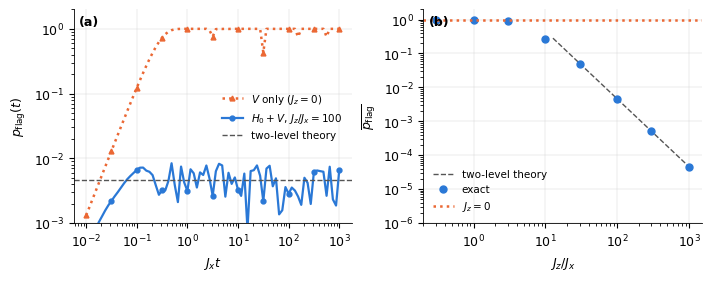

In [25]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6})
blue, orange, grey = "#2a78d6", "#eb6834", "#555555"     # validated colour-blind-safe pair + neutral
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.7), constrained_layout=True)

ax[0].loglog(times, off, color=orange, ls=":", lw=1.8, marker="^", ms=3.5, markevery=8, label=r"$V$ only ($J_z=0$)")
ax[0].loglog(times, on,  color=blue, lw=1.6, marker="o", ms=3.5, markevery=8, label=rf"$H_0+V$, $J_z/J_x={Jz_main:g}$")
ax[0].axhline(theory(Jz_main), color=grey, ls="--", lw=1, label="two-level theory")
ax[0].set_xlabel(r"$J_x t$"); ax[0].set_ylabel(r"$p_{\rm flag}(t)$"); ax[0].set_ylim(1e-3, 2)
ax[0].legend(frameon=False, fontsize=7.5, loc="center right")

Jg = np.logspace(np.log10(Jz_scan[0]), np.log10(Jz_scan[-1]), 200)
th = np.array([theory(j) for j in Jg]); ok = th < 0.3       # draw theory only where perturbation theory applies
ax[1].loglog(Jg[ok], th[ok], color=grey, ls="--", lw=1, label="two-level theory")
ax[1].loglog(Jz_scan, avg, "o", color=blue, ms=5, label="exact")
ax[1].axhline(avg_off, color=orange, ls=":", lw=1.8, label=r"$J_z=0$")
ax[1].set_xlabel(r"$J_z/J_x$"); ax[1].set_ylabel(r"$\overline{p_{\rm flag}}$"); ax[1].set_ylim(1e-6, 2)
ax[1].legend(frameon=False, fontsize=7.5, loc="lower left")

for A, tag in zip(ax, "ab"):
    A.grid(True, which="major", lw=0.3, color="#d0d0d0")
    A.text(0.02, 0.97, f"({tag})", transform=A.transAxes, va="top", fontweight="bold")
fig.savefig("Fig2.pdf"); fig.savefig("Fig2.png", dpi=200)
plt.show()